---

```
# Adult Census Income — exploração inicial\
# A tarefa associada é de classificação binária: prever se a renda anual de uma pessoa é superior a US$ 50 mil (>50K) ou não (<=50K)
# a partir de 14 atributos demográficos e ocupacionais. É um dos datasets mais usados como benchmark em aprendizado de máquina e,
# por conter sexo e raça, também em estudos de justiça algorítmica (fairness).

base:  https://www.kaggle.com/datasets/uciml/adult-census-income
```




In [37]:
# import de bibliotecas
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from os.path import join
from collections import Counter

from sklearn.model_selection import train_test_split #

from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import(train_test_split, cross_val_score, StratifiedKFold)

from sklearn.tree import(DecisionTreeClassifier, plot_tree, export_text, _tree)

from sklearn.metrics import(accuracy_score, classification_report)

from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix)

from traducao import (
    traduzir, traduzir_dataframe, dicionario_dados, rotulo, ordem_classes,
    COLUNAS, TIPOS, AUSENTE_PT,
)




In [3]:
df = pd.read_csv("adult.csv") # base de dados

print(df.head())

   age workclass  fnlwgt     education  education.num marital.status  \
0   90         ?   77053       HS-grad              9        Widowed   
1   82   Private  132870       HS-grad              9        Widowed   
2   66         ?  186061  Some-college             10        Widowed   
3   54   Private  140359       7th-8th              4       Divorced   
4   41   Private  264663  Some-college             10      Separated   

          occupation   relationship   race     sex  capital.gain  \
0                  ?  Not-in-family  White  Female             0   
1    Exec-managerial  Not-in-family  White  Female             0   
2                  ?      Unmarried  Black  Female             0   
3  Machine-op-inspct      Unmarried  White  Female             0   
4     Prof-specialty      Own-child  White  Female             0   

   capital.loss  hours.per.week native.country income  
0          4356              40  United-States  <=50K  
1          4356              18  United-States

In [4]:
df.info()

print('\n\n Quantidade de Valores ausentes: ' ,df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


 Quantidade de Valores ausentes:  age               0
workclass         0
fnlwgt           

In [5]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [6]:
dicionario = dicionario_dados()
dicionario

,Coluna original,Coluna (pt),Rótulo,Tipo,Nº de classes,Descrição
0,age,idade,Idade,numérica,<NA>,"Idade da pessoa, em anos."
1,workclass,classe_trabalho,Classe de trabalho,categórica,8,"Tipo de vínculo/empregador: setor privado, gov..."
2,fnlwgt,peso_amostral,Peso amostral,numérica,<NA>,Peso amostral (final weight) atribuído pelo Ce...
3,education,escolaridade,Escolaridade,categórica (ordinal),16,Maior nível de escolaridade concluído.
4,education.num,escolaridade_num,Escolaridade (nível numérico),numérica (ordinal),<NA>,Codificação ordinal da escolaridade (1 = pré-e...
5,marital.status,estado_civil,Estado civil,categórica,7,Estado civil.
6,occupation,ocupacao,Ocupação,categórica,14,Grupo ocupacional (categorias amplas do censo).
7,relationship,relacao_familiar,Relação familiar,categórica,6,Relação da pessoa com o responsável pelo domic...
8,race,raca,Raça,categórica,5,Raça declarada (categorias do censo dos EUA).
9,sex,sexo,Sexo,categórica (binária),2,Sexo.


In [ ]:
df = traduzir_dataframe(df)

df.head()

In [7]:
# verificando se existe valores ausentes preenchidos incorretamente na base original
# Depois, contabilizamos o total para cada coluna.
df.replace(' ?', np.nan, inplace=True)
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,0
relationship,0
race,0
sex,0


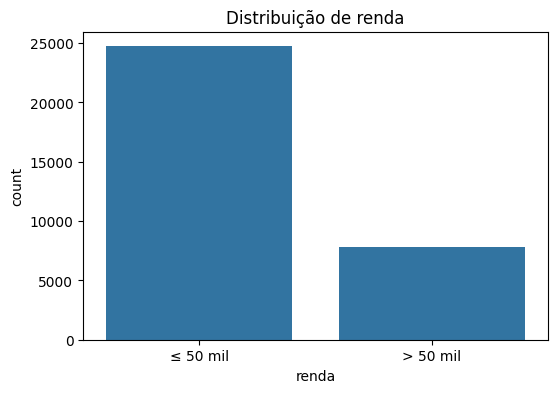

_________________________
Interpretação da avaliação:
24,720 pessoas possuem uma renda <= 50 mil/ano.
7,841 pessoas possuem uma renda maior que 50 mil/ano.
_________________________


In [8]:
# Verificando a distribuição de renda
df = traduzir_dataframe(df)

plt.figure(figsize=(6, 4))

sns.countplot(x ='renda',data = df)

plt.title("Distribuição de renda")
plt.show()

contagem = df['renda'].value_counts()

menor50 = contagem.get('≤ 50 mil', 0)
maior50 = contagem.get('> 50 mil', 0)

print('_' * 25)
print('Interpretação da avaliação:')
print(f'{menor50:,} pessoas possuem uma renda <= 50 mil/ano.')
print(f'{maior50:,} pessoas possuem uma renda maior que 50 mil/ano.')
print('_' * 25)

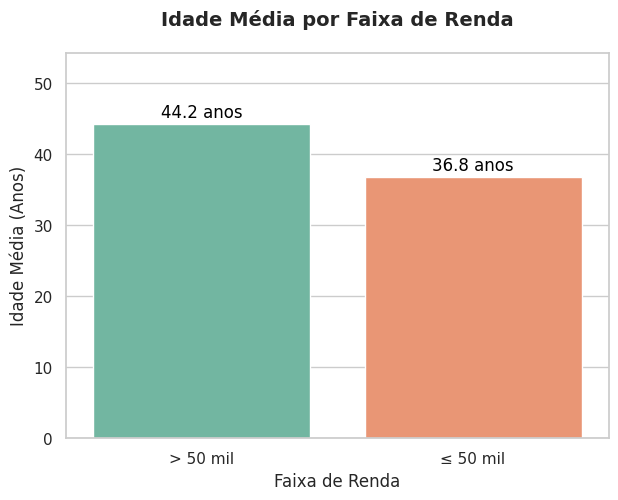

_______________________________________________________
Legenda
$ Quem ganha até 50 mil no ano tem, em média, 36.8 anos.
$ Quem ganha mais de 50 mil no ano tende a ser mais velho, com média de 44.2 anos.
Resumindo: Pessoas mais velhas tendem a ter uma renda maior!
_______________________________________________________


In [12]:
df = traduzir_dataframe(df)

coluna_idade = 'idade' if 'idade' in df.columns else 'age'

# Calculando a média de idade para cada grupo de renda
# O grafico apresenta a média exata
df_media = df.groupby('renda')[coluna_idade].mean().reset_index()

# Configurar o tamanho do gráfico
plt.figure(figsize=(7, 5))
sns.set_theme(style="whitegrid")

# Criar o gráfico de colunas
grafico = sns.barplot(
    x='renda',
    y=coluna_idade,
    data=df_media,
    palette="Set2",
    hue='renda',
    legend=False
)

# Adicionar os números EM CIMA de cada barra
# Isso melhora a avaliação do grafico
for p in grafico.patches:
    altura = p.get_height()
    grafico.annotate(
        f'{altura:.1f} anos',
        (p.get_x() + p.get_width() / 2., altura),
        ha='center',
        va='baseline',
        fontsize=12,
        color='black',
        xytext=(0, 5),
        textcoords='offset points'
    )

# formatação dos eixos
plt.title("Idade Média por Faixa de Renda", fontsize=14, pad=20, fontweight='bold')
plt.xlabel("Faixa de Renda", fontsize=12)
plt.ylabel("Idade Média (Anos)", fontsize=12)

# Definindo o limite do eixo Y, isso vai apresentar o texto sem corte
plt.ylim(0, df_media[coluna_idade].max() + 10)

plt.show()

# Interpretação dos resultados
media_menor = df_media.loc[df_media['renda'] == '≤ 50 mil', coluna_idade].values[0]
media_maior = df_media.loc[df_media['renda'] == '> 50 mil', coluna_idade].values[0]

print("_" * 55)
print("Análise")
print(f"$ Quem ganha até 50 mil ao ano tem, em média, {media_menor:.1f} anos.")
print(f"$ Quem ganha mais de 50 mil ao ano tende a ser mais velho, com média de {media_maior:.1f} anos.")
print('Resumindo: Pessoas mais velhas tendem a ter uma renda maior!')
print("_" * 55)


In [13]:
def formatar_int(n):
    return f"{int(n):,}".replace(",", ".")


def formatar_pct(p):
    if 0 < p < 0.05:
        return "<0,1%"
    return f"{p:.1f}%".replace(".", ",")


def n_distintos(serie):
    """Número de valores distintos, sem contar o marcador de ausente."""
    return serie[serie != AUSENTE_PT].nunique()


def classes_ordenadas(serie):
    """Classes da mais frequente para a menos frequente, sem o marcador de ausente."""
    return [c for c in serie.value_counts().index if c != AUSENTE_PT]


def eixo_compacto(ax, eixo="x"):
    fmt = FuncFormatter(lambda v, _: (f"{v / 1000:g}K" if v >= 1000 else f"{v:g}").replace(".", ","))
    (ax.xaxis if eixo == "x" else ax.yaxis).set_major_formatter(fmt)


def tabela_frequencia(serie, ordem=None):
    """Contagem e percentual de cada classe, por frequência ou na ordem informada.

    Classes presentes nos dados mas ausentes de `ordem` (ex.: 'Não informado') vão para o fim,
    para que nenhuma linha seja descartada e os percentuais continuem somando 100%."""
    contagem = serie.value_counts(dropna=False)
    if ordem is not None:
        presentes = [c for c in ordem if c in contagem.index]
        restantes = [c for c in contagem.index if c not in presentes]
        contagem = contagem.reindex(presentes + restantes)
    tabela = pd.DataFrame({
        "Contagem": contagem,
        "Percentual (%)": (contagem / contagem.sum() * 100).round(2),
    })
    tabela.index.name = "Classe"
    return tabela


def grafico_barras(contagem, titulo, max_classes=20, rotular=True, xlabel="Contagem", total=None):
    """Barras horizontais em um só tom. Acima de `max_classes`, a cauda vira 'Outros' (só no gráfico).

    `total` é o denominador dos percentuais nos rótulos (padrão: soma das barras)."""
    contagem = contagem.copy()
    cores = [AZUL] * len(contagem)
    if max_classes is not None and len(contagem) > max_classes:
        # agrupa as classes MENOS frequentes, seja qual for a ordem das barras
        principais = contagem.nlargest(max_classes).index
        cauda = contagem.drop(principais)
        contagem = pd.concat([
            contagem[contagem.index.isin(principais)],
            pd.Series({f"Outros ({len(cauda)} classes)": cauda.sum()}),
        ])
        cores = [AZUL] * max_classes + [CINZA_OUTROS]

    total = total if total is not None else contagem.sum()
    posicoes = np.arange(len(contagem))[::-1]
    altura = max(2.4, 0.42 * len(contagem) + 1.2)

    fig, ax = plt.subplots(figsize=(9, altura))
    ax.barh(posicoes, contagem.values, color=cores, height=0.62)
    ax.set_yticks(posicoes, [str(c) for c in contagem.index])
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    if rotular:
        for pos, valor in zip(posicoes, contagem.values):
            ax.text(valor + contagem.max() * 0.012, pos,
                    f"{formatar_int(valor)}  ({formatar_pct(valor / total * 100)})",
                    va="center", fontsize=8.5, color=TEXTO_SEC)
    ax.set_xlim(0, contagem.max() * 1.24)
    eixo_compacto(ax, "x")
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    plt.tight_layout()
    plt.show()


def distribuicao_categorica(df, coluna, ordem=None, max_classes=20, titulo=None):
    """Gráfico de barras + tabela (contagem e %) da distribuição das classes de uma coluna."""
    tabela = tabela_frequencia(df[coluna], ordem=ordem)
    titulo = titulo or f"{rotulo(coluna)}: distribuição das classes (n = {formatar_int(len(df))})"
    grafico_barras(tabela["Contagem"], titulo, max_classes=max_classes)
    display(tabela)
    return tabela


def distribuicao_numerica(df, coluna, bins=20, titulo=None, somente_positivos=False):
    """Histograma + resumo estatístico + tabela de contagem por faixa de uma coluna numérica.

    A tabela usa exatamente as barras do histograma: faixas [a, b), fechadas à esquerda
    e abertas à direita; apenas a última faixa inclui o limite superior."""
    serie = df[coluna]
    if somente_positivos:
        serie = serie[serie > 0]

    nome = rotulo(coluna) + (" (apenas valores > 0)" if somente_positivos else "")
    resumo = serie.describe().rename({
        "count": "n", "mean": "média", "std": "desvio padrão", "min": "mínimo",
        "25%": "Q1 (25%)", "50%": "mediana", "75%": "Q3 (75%)", "max": "máximo",
    }).to_frame(nome).T

    # As faixas da tabela são as mesmas barras do histograma (np.histogram):
    # fechadas à esquerda e abertas à direita, [a, b); só a última inclui o limite superior.
    contagens, bordas = np.histogram(serie, bins=bins)
    faixas = [f"[{formatar_int(a)}, {formatar_int(b)})" for a, b in zip(bordas[:-1], bordas[1:])]
    faixas[-1] = faixas[-1][:-1] + "]"
    tabela = pd.DataFrame({
        "Contagem": contagens,
        "Percentual (%)": (contagens / contagens.sum() * 100).round(2),
    }, index=pd.Index(faixas, name="Faixa"))

    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.bar(bordas[:-1], contagens, width=np.diff(bordas), align="edge",
           color=AZUL, edgecolor="white", linewidth=1.5)
    ax.grid(axis="x", visible=False)
    ax.set_title(titulo or f"{rotulo(coluna)}: distribuição (n = {formatar_int(len(serie))})")
    ax.set_xlabel(rotulo(coluna))
    ax.set_ylabel("Contagem")
    eixo_compacto(ax, "x")
    eixo_compacto(ax, "y")
    plt.tight_layout()
    plt.show()

    display(resumo)
    display(tabela)
    return tabela

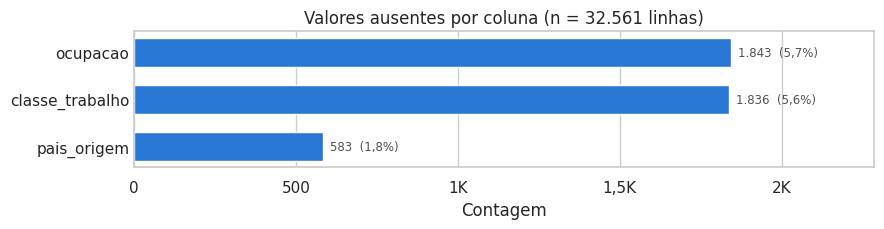

,Ausentes,Percentual (%)
Coluna,,
ocupacao,1843,5.66
classe_trabalho,1836,5.64
pais_origem,583,1.79


Linhas sem classe de trabalho E sem ocupação: 1.836
Linhas em que só a ocupação está ausente: 7 -> classe de trabalho delas: {'Nunca trabalhou': 7}
Linhas duplicadas (todas as colunas iguais): 24
Linhas com pelo menos um ausente: 2.399 (7,4%)


In [14]:
from matplotlib.ticker import FuncFormatter
# Stylo dos graficos
AZUL = "#2a78d6"
CINZA_OUTROS = "#c3c2b7"
TEXTO = "#0b0b0b"
TEXTO_SEC = "#52514e"
GRADE = "#e6e5e2"

ausentes = (df == AUSENTE_PT).sum()
tab_ausentes = pd.DataFrame({
    "Ausentes": ausentes,
    "Percentual (%)": (ausentes / len(df) * 100).round(2),
})
tab_ausentes.index.name = "Coluna"
tab_ausentes = tab_ausentes[tab_ausentes["Ausentes"] > 0].sort_values("Ausentes", ascending=False)

grafico_barras(tab_ausentes["Ausentes"], f"Valores ausentes por coluna (n = {formatar_int(len(df))} linhas)",
               total=len(df))
display(tab_ausentes)

ambos = ((df["classe_trabalho"] == AUSENTE_PT) & (df["ocupacao"] == AUSENTE_PT)).sum()
linhas_com_ausente = (df == AUSENTE_PT).any(axis=1).sum()
so_ocupacao = df.loc[(df["ocupacao"] == AUSENTE_PT) & (df["classe_trabalho"] != AUSENTE_PT), "classe_trabalho"]
print(f"Linhas sem classe de trabalho E sem ocupação: {formatar_int(ambos)}")
print(f"Linhas em que só a ocupação está ausente: {formatar_int(len(so_ocupacao))} "
      f"-> classe de trabalho delas: {so_ocupacao.value_counts().to_dict()}")
print(f"Linhas duplicadas (todas as colunas iguais): {formatar_int(df.duplicated().sum())}")
print(f"Linhas com pelo menos um ausente: {formatar_int(linhas_com_ausente)} "
      f"({formatar_pct(linhas_com_ausente / len(df) * 100)})")

<Figure size 800x400 with 0 Axes>

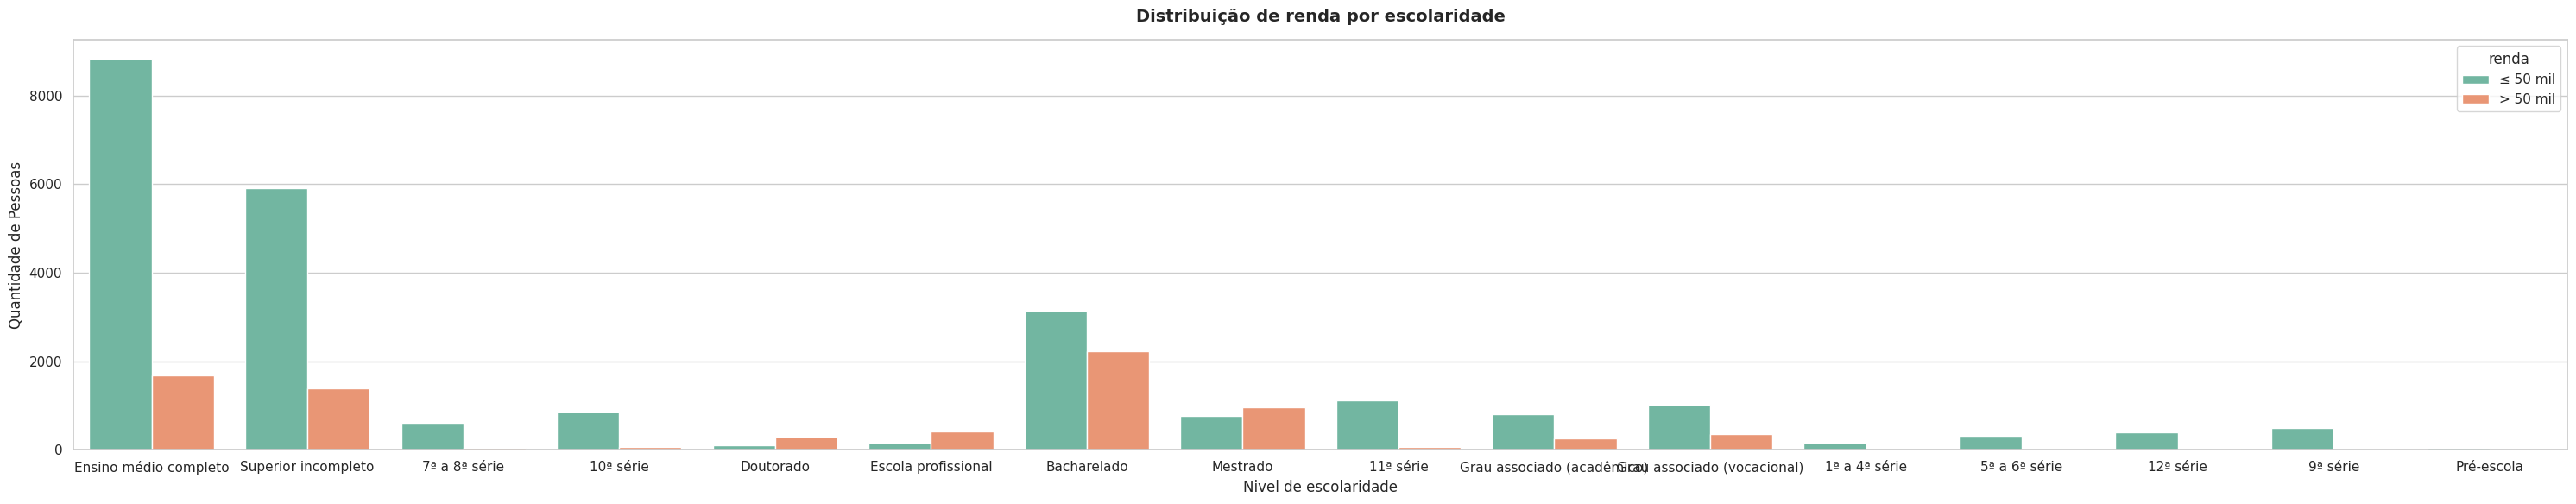

_________________________
Resultado:
ANÁLISE DE MAIOR FREQUÊNCIA (RENDA > 50 MIL):
• A escolaridade que aparece com maior frequência é: 'Bacharelado'
• Total de pessoas nessa categoria com alta renda: 2,221 indivíduos.

TOP 3 ESCOLARIDADES COM MAIOR NÚMERO DE PESSOAS (> 50 mil):
 1º. Bacharelado: 2,221 pessoas
 2º. Ensino médio completo: 1,675 pessoas
 3º. Superior incompleto: 1,387 pessoas
-----------------------------------------------------------------

Acompanhamento por Nível: 10ª série
871 pessoas tem uma renda ≤ 50 mil/ano
62 pessoas tem uma renda > 50 mil/ano

Acompanhamento por Nível: 11ª série
1,115 pessoas tem uma renda ≤ 50 mil/ano
60 pessoas tem uma renda > 50 mil/ano

Acompanhamento por Nível: 12ª série
400 pessoas tem uma renda ≤ 50 mil/ano
33 pessoas tem uma renda > 50 mil/ano

Acompanhamento por Nível: 1ª a 4ª série
162 pessoas tem uma renda ≤ 50 mil/ano
6 pessoas tem uma renda > 50 mil/ano

Acompanhamento por Nível: 5ª a 6ª série
317 pessoas tem uma renda ≤ 50 mil/ano

In [15]:
# Verificando a distribuição de renda por escolaridade
df = traduzir_dataframe(df)

df_rico = df[df['renda'] == '> 50 mil']

contagem_escolaridade = df_rico['escolaridade'].value_counts()

total_ocorrencia = contagem_escolaridade.max()


plt.figure(figsize=(8, 4))


escolaridade = 'escolaridade' if 'escolaridade' in df.columns else 'escolaridade'

plt.figure(figsize=(30, 6))
sns.set_theme(style="whitegrid")

grafico = sns.countplot(x=escolaridade, hue='renda', data=df, palette='Set2')

plt.title('Distribuição de renda por escolaridade', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Nivel de escolaridade', fontsize=12)
plt.ylabel('Quantidade de Pessoas', fontsize=12)

plt.tight_layout()
plt.show()

print('_' * 25)
print('Resultado:')
cruzamento_dados = df.groupby([escolaridade, 'renda']).size().unstack(fill_value=0 )

escolaridade_maior_frequencia = contagem_escolaridade.idxmax()

print("ANÁLISE DE MAIOR FREQUÊNCIA (RENDA > 50 MIL):")
print(f"• A escolaridade que aparece com maior frequência é: '{escolaridade_maior_frequencia}'")
print(f"• Total de pessoas nessa categoria com alta renda: {total_ocorrencia:,} indivíduos.")


print("\nTOP 3 ESCOLARIDADES COM MAIOR NÚMERO DE PESSOAS (> 50 mil):")
for i, (esc, total) in enumerate(contagem_escolaridade.head(3).items(), 1):
    print(f" {i}º. {esc}: {total:,} pessoas")
print("-" * 65)

for escolaridade in cruzamento_dados.index:
  menor50 = cruzamento_dados.loc[escolaridade, '≤ 50 mil'] if '≤ 50 mil' in cruzamento_dados else 0
  maior50 = cruzamento_dados.loc[escolaridade, '> 50 mil'] if '> 50 mil' in cruzamento_dados else 0

  print(f'\nAcompanhamento por Nível: {escolaridade}')
  print(f'{menor50:,} pessoas tem uma renda ≤ 50 mil/ano')
  print(f'{maior50:,} pessoas tem uma renda > 50 mil/ano')
print('_' * 25)

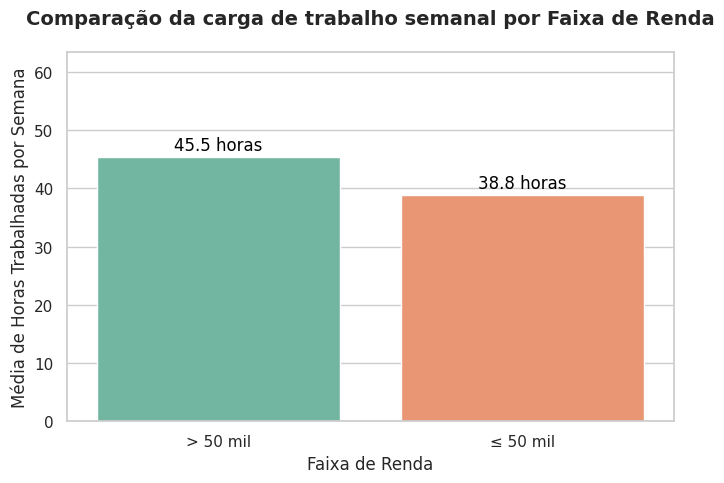

__________________________________________________
Pessoas no grupo de Renda ≤ 50 mil/ano: Trabalha, em média, 38.8 horas por semana.
Pessoas no grupo de Renda > 50 mil/ano: Trabalha, em média, 45.5 horas por semana.
__________________________________________________
_________________________________________________________________
Conclusão:
 Sim, as pessoas com maiores renda, costumam trabalhar mais!
 Eles dedicam, em média, 6.6 horas a mais por semana
 do que o grupo que ganha menos.
_________________________________________________________________


In [17]:
#Comparação a carga de trabalho por faixa de renda
df = traduzir_dataframe(df)

coluna_horas = 'horas_semana'

df_media_horas = df.groupby('renda')[coluna_horas].mean().reset_index()


media_menor = df_media_horas.loc[df_media_horas['renda'] == '≤ 50 mil', coluna_horas].values[0]
media_maior = df_media_horas.loc[df_media_horas['renda'] == '> 50 mil', coluna_horas].values[0]
diferenca_horas = media_maior - media_menor


plt.figure(figsize=(7,5))
sns.set_theme(style='whitegrid')

grafico = sns.barplot(x='renda', y=coluna_horas, data=df_media_horas, palette='Set2',hue='renda',legend=False)


for p in grafico.patches:
    altura = p.get_height()
    grafico.annotate(
        f'{altura:.1f} horas',
        (p.get_x() + p.get_width() / 2., altura),
        ha='center',
        va='baseline',
        fontsize=12,
        color='black',
        xytext = (0, 5),
        textcoords='offset points'
    )


plt.title('Comparação da carga de trabalho semanal por Faixa de Renda', fontsize=14, pad=20, fontweight='bold')
plt.xlabel('Faixa de Renda', fontsize=12)
plt.ylabel('Média de Horas Trabalhadas por Semana', fontsize=12)

plt.ylim(0, max(media_menor, media_maior) + 18)

plt.tight_layout()
plt.show()

print('_' * 50)
print(f'Pessoas no grupo de Renda ≤ 50 mil/ano: Trabalha, em média, {media_menor:.1f} horas por semana.')
print(f'Pessoas no grupo de Renda > 50 mil/ano: Trabalha, em média, {media_maior:.1f} horas por semana.')
print('_' * 50)


print('_' * 65)
print('Conclusão:')

if media_maior > media_menor:
  print(f" Sim, as pessoas com maiores renda, costumam trabalhar mais!")
  print(f" Eles dedicam, em média, {diferenca_horas:.1f} horas a mais por semana")
  print(f" do que o grupo que ganha menos.")

else:
  print(f" Não, o grupo de maior renda não trabalha mais horas semanais")
  print(f" do que o grupo de menor.")

print('_' * 65)

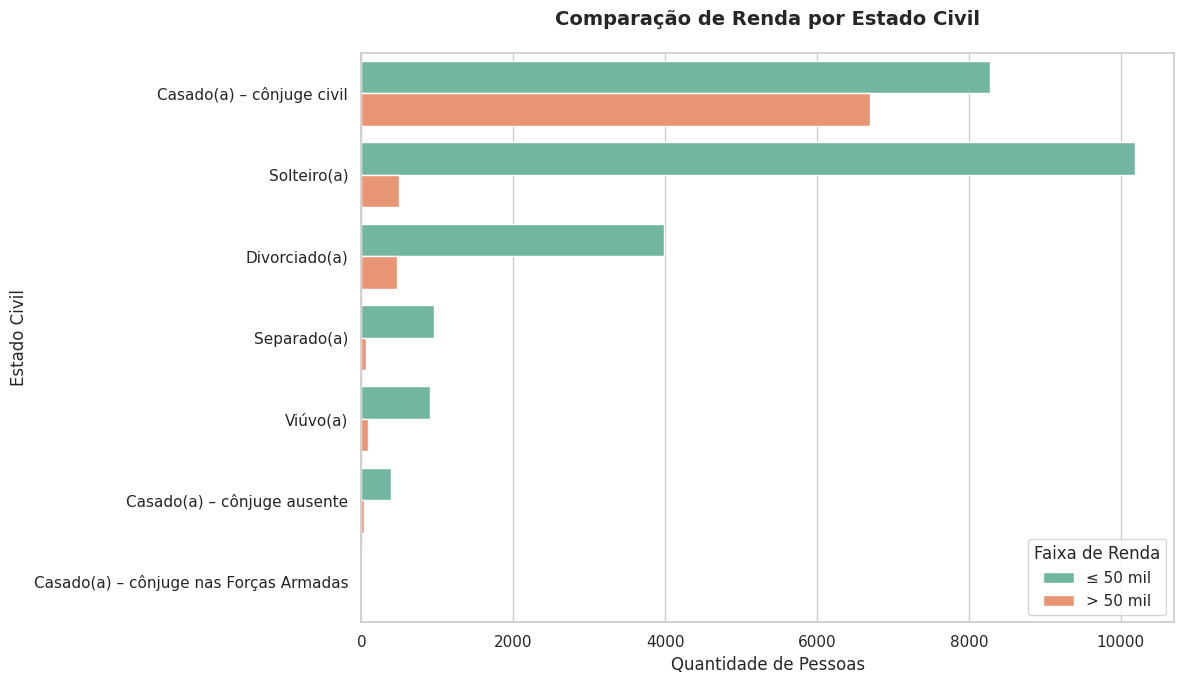

______________________________
Avaliação da Renda por Estado Cívil
Destaque: O estado civil com mais pessoas na faixa > 50 mil é 'Casado(a) – cônjuge civil'
com um total de 6,692 indivíduos.

 Avaliação por Estado Cívil:

Status: Casado(a) – cônjuge ausente
   384 pessoas têm uma renda ≤ 50 mil/ano
   34 pessoas têm uma renda > 50 mil/ano

Status: Casado(a) – cônjuge civil
   8,284 pessoas têm uma renda ≤ 50 mil/ano
   6,692 pessoas têm uma renda > 50 mil/ano

Status: Casado(a) – cônjuge nas Forças Armadas
   13 pessoas têm uma renda ≤ 50 mil/ano
   10 pessoas têm uma renda > 50 mil/ano

Status: Divorciado(a)
   3,980 pessoas têm uma renda ≤ 50 mil/ano
   463 pessoas têm uma renda > 50 mil/ano

Status: Separado(a)
   959 pessoas têm uma renda ≤ 50 mil/ano
   66 pessoas têm uma renda > 50 mil/ano

Status: Solteiro(a)
   10,192 pessoas têm uma renda ≤ 50 mil/ano
   491 pessoas têm uma renda > 50 mil/ano

Status: Viúvo(a)
   908 pessoas têm uma renda ≤ 50 mil/ano
   85 pessoas têm uma ren

In [29]:
#Comparação da Renda por estado civil
df = traduzir_dataframe(df)

estado_civil = 'estado_civil' if 'estado_civil' in df.columns else 'marital.status'

#modelagem grafica
plt.figure(figsize=(12,7))
sns.set_theme(style='whitegrid')

grafico = sns.countplot(
    y=estado_civil,
    hue='renda',
    data=df,
    palette='Set2',
    order=df[estado_civil].value_counts().index # ordenação por estado civil.
)

plt.title('Comparação de Renda por Estado Civil', fontsize=14, pad=20, fontweight='bold')
plt.xlabel('Quantidade de Pessoas', fontsize=12)
plt.ylabel('Estado Civil', fontsize=12)
plt.legend(title='Faixa de Renda', loc='lower right')


plt.tight_layout()
plt.show()

print('_'*30)
print('Avaliação da Renda por Estado Cívil')

avaliacao_estado = df.groupby(['estado_civil', 'renda']).size().unstack(fill_value=0)

if '> 50 mil' in avaliacao_estado.columns:
  maior_grupo_rico = avaliacao_estado['> 50 mil'].idxmax()
  total_grupo_rico = avaliacao_estado['> 50 mil'].max()

  print(f"Destaque: O estado civil com mais pessoas na faixa > 50 mil é '{maior_grupo_rico}'")
  print(f"com um total de {total_grupo_rico:,} indivíduos.")


print("\n Avaliação por Estado Cívil:")
for civil_status in avaliacao_estado.index:
    menor50 = avaliacao_estado.loc[civil_status, '≤ 50 mil'] if '≤ 50 mil' in avaliacao_estado.columns else 0
    maior50 = avaliacao_estado.loc[civil_status, '> 50 mil'] if '> 50 mil' in avaliacao_estado.columns else 0

    print(f"\nStatus: {civil_status}")
    print(f"   {menor50:,} pessoas têm uma renda ≤ 50 mil/ano")
    print(f"   {maior50:,} pessoas têm uma renda > 50 mil/ano")

print('_'*30)



In [ ]:

# carregando a base de dados

df = pd.read_csv("adult.csv")
df = traduzir_dataframe(df)
df.head()

In [ ]:
# Análise inicial
print(df.info())
print(df.describe())
print(df.isnull().sum())

In [ ]:
# tratando valores ausentes
# Verificando se existe registros contendo '?'

df.replace("?", np.nan, inplace=True)
df.replace(" ?", np.nan, inplace=True)

print(df.isnull().sum())

# Remover registros incompletos

df.dropna(inplace=True)

print("Quantidade de registros:", len(df))

In [ ]:
# Análise exploratoria
# Distribuição da variável alvo

plt.figure(figsize=(6,4))
sns.countplot(
    data=df,
    x="renda"
)

plt.title("Distribuição da renda")
plt.show()

In [ ]:

# Preparação dos dados
X = df.drop("renda", axis=1)

y = df["renda"]

# codigficando as variaveis categoricas.
X = pd.get_dummies(
    X,
    drop_first=True
)

# Transformação da variavel alvo
le = LabelEncoder()
y = le.fit_transform(y)

In [ ]:
# Divisão da base para Treinamento e Teste

SEED = 10
X_train, X_test, y_train, y_teste = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

#arvore inicial
arvore = DecisionTreeClassifier(
    random_state=SEED
)

arvore.fit(
    X_train,
    y_train
)

# validação cruzada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

scores = cross_val_score(
    arvore,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Acurácia por Fold")
print(scores)
print()
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

In [ ]:
#Poda da árvore

path = arvore.cost_complexity_pruning_path(
    X_train,
    y_train
)

ccp_alphas = path.ccp_alphas

alpha_scores = []

for alpha in ccp_alphas:
  modelo = DecisionTreeClassifier(
      random_state=SEED,
      ccp_alpha=alpha
  )

  score = cross_val_score(
      modelo,
      X_train,
      y_train,
      cv=5,
      scoring="accuracy"
  ).mean()

  alpha_scores.append(score)

  best_alpha = ccp_alphas[
      np.argmax(alpha_scores)
  ]

  print("Melhor alpha:", best_alpha)

In [ ]:
#árvore usando poda
arvore = DecisionTreeClassifier(
    random_state = SEED,
    ccp_alpha=best_alpha,
    max_depth=5
)

arvore.fit(
    X_train,
    y_train
)

#avaliação
pred = arvore.predict(X_test)

print(classification_report(
    y_teste,
    pred
))

print(
    "Accuracy:",
    accuracy_score(
        y_teste,
        pred
    )
)

In [ ]:
#Matriz de confusão
cm = confusion_matrix(
    y_teste,
    pred
)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Matris de Confusão')
plt.show()

In [ ]:
# Importancia das variáveis
importancias = pd.DataFrame({

    "Variavel": X.columns,
    "Importancia": arvore.feature_importances_

})

importancias = importancias.sort_values(
    by="Importancia",
    ascending=False
)

print(importancias.head(20))

#Geração do grafico
plt.figure(figsize=(10,6))

sns.barplot(
    data=importancias.head(15),
    x="Importancia",
    y="Variavel"
)

plt.title(
    "Variáveis mais importantes"
)

plt.show()

In [ ]:
#Desenho da distribuição avaliativa atraves da árvore de decisão
plt.figure(
    figsize=(40,12)
)

plot_tree(
    arvore,
    feature_names=X.columns,
    class_names=["<=50K", ">50K"],
    filled=True,
    rounded=True
)

plt.show()

#Extraindo as regras.
regras = export_text(
    arvore,
    feature_names=list(X.columns)
)

print(regras)

Modificando a interpretação da arvore de decisão para verificar se ao modificar conseguimos extrar insids diferentes.


Quais variaveis mais influencial na renda?

In [35]:
top10 = importancias.sort_values(
    by="Importancia",
    ascending=False
).head(10)

print(top10)

NameError: name 'importancias' is not defined

In [38]:
#Realizar treinamento novamente!

df = pd.read_csv("adult.csv") # leitura da base

df = traduzir_dataframe(df)

# tratando as celulas sem valores
df.replace("?", np.nan, inplace=True)
df.replace(" ?", np.nan, inplace=True)

df.dropna(inplace=True)

X = df.drop("renda", axis=1)
y = df["renda"]


X =pd.get_dummies(X, drop_first=True) #Transformando variaveis em categórias

#realizando o Treinamento
#Arvore inicial
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=10,
    stratify=y
)


arvore = DecisionTreeClassifier(random_state = 10)

arvore.fit(X_train, y_train)




DecisionTreeClassifier(random_state=10)

In [39]:
# Aplicando poda

path = arvore.cost_complexity_pruning_path(X_train, y_train)

ccp_alphas = path.ccp_alphas

scores = []


for alpha in ccp_alphas:
  modelo = DecisionTreeClassifier(random_state=10, ccp_alpha=alpha)

  modelo.fit(X_train, y_train)

  scores.append(
      modelo.score(
          X_test,
          y_test
      )
    )

  melhor_alpha = ccp_alphas[
      np.argmax(scores)
  ]

  print('Melhor alpha:',
        melhor_alpha
        )

Melhor alpha: 0.0
Melhor alpha: 0.0
Melhor alpha: 0.0
Melhor alpha: 0.0
Melhor alpha: 2.1552653131600503e-05
Melhor alpha: 2.1682434473132178e-05
Melhor alpha: 2.1682434473132178e-05
Melhor alpha: 2.1682434473132178e-05
Melhor alpha: 2.1682434473132178e-05
Melhor alpha: 2.1682434473132178e-05
Melhor alpha: 2.1682434473132178e-05
Melhor alpha: 2.1682434473132178e-05
Melhor alpha: 2.1682434473132178e-05
Melhor alpha: 2.1682434473132178e-05
Melhor alpha: 2.1682434473132178e-05
Melhor alpha: 2.1682434473132178e-05
Melhor alpha: 2.5593775593775592e-05
Melhor alpha: 2.5593775593775592e-05
Melhor alpha: 2.5593775593775592e-05
Melhor alpha: 2.5593775593775592e-05
Melhor alpha: 2.5593775593775592e-05
Melhor alpha: 2.5593775593775592e-05
Melhor alpha: 2.5593775593775592e-05
Melhor alpha: 2.6812526812526816e-05
Melhor alpha: 2.6812526812526816e-05
Melhor alpha: 2.716074144645574e-05
Melhor alpha: 2.716074144645574e-05
Melhor alpha: 2.716074144645574e-05
Melhor alpha: 2.716074144645574e-05
Melhor 

In [42]:
# Construindo a arvore

arvore = DecisionTreeClassifier(
    random_state=10,
    ccp_alpha=melhor_alpha,
    max_depth=5
)

arvore.fit(
    X_train,
    y_train
)

DecisionTreeClassifier(ccp_alpha=np.float64(0.00015040495817286509),
                       max_depth=5, random_state=10)

In [43]:

# Extraindo regras

def extrair_regras(arvore, feature_names, class_names):
  tree = arvore.tree_

  regras = []

  def percorrer(no, caminho): #função de navegação recursiva
    if tree.feature[no] != _tree.TREE_UNDEFINED: # verificando se o nó atual corresponde ao nó de decisão
      feature = feature_names[tree.feature[no]] # descobrindo o nome da variavel

      threshold = tree.threshold[no] # Identifica o valor de corte usado para a decisão

      #Regras para percorer os nos lado esquerdo e lado direito
      regra_esq = caminho + [
          f'{feature} <= {threshold:.2f}'
      ]

      percorrer(
          tree.children_left[no],
          regra_esq
      )

      regra_dir = caminho + [
          f'{feature} > {threshold:.2f}'
      ]

      percorrer(
          tree.children_right[no],
          regra_dir
      )

    else: # Se o nó atual for o nó folha, o codigo entra no else

      # verificando os votos no nó folha e escolhe a classe com maior quantidade de amostra
      classe = class_names[
          tree.value[no][0].argmax()
          ]

      amostras = tree.n_node_samples[no] # Verifica a quantidade de pessoas da base caiu dentro da folha

      # Calculando a assertividade da decisão da árvore
      probabilidade = (
          tree.value[no][0].max() / tree.value[no][0].sum()
      )

      #Criando o dicionario das regras com o resultado
      regras.append({
          'Classe': classe,
          'Amostras': amostras,
          'Probabilidade': round(probabilidade * 100, 2),

          'Regra': 'AND'.join(caminho)
      })

  percorrer(0, [])

  return pd.DataFrame(regras)



#Apresentando as regras

regras = extrair_regras(
    arvore,
    list(X.columns),
    ['<=50K', '>50k']
)

print(regras)


   Classe  Amostras  Probabilidade  \
0    >50k      7926          98.68   
1    >50k      1737          93.61   
2   <=50K        35          60.00   
3    >50k         7         100.00   
4    >50k       831          97.59   
5    >50k       756          85.32   
6    >50k       144          95.83   
7    >50k       632          66.30   
8    >50k         3         100.00   
9    >50k         2         100.00   
10  <=50K       218          98.62   
11   >50k      1125          90.49   
12   >50k      5643          68.60   
13  <=50K       190          95.79   
14   >50k        73          73.97   
15  <=50K       364          98.08   
16   >50k       205          63.41   
17  <=50K      2137          66.35   
18  <=50K       276          98.19   
19  <=50K       488          99.59   

                                                Regra  
0   estado_civil_Casado(a) – cônjuge civil <= 0.50...  
1   estado_civil_Casado(a) – cônjuge civil <= 0.50...  
2   estado_civil_Casado(a) – cônj

In [49]:
# Regras de conhecimento adquirido.

def interpretar_regra(regra):

    conhecimento = regra.split('AND')
    frases = []

    if "ganho_capital >" in regra:
        conhecimento.append(
            "possuem elevados ganhos de capital"
        )

    if "ganho_capital <=" in regra:
        conhecimento.append(
            "não apresentam ganhos significativos de capital"
        )

    if "escolaridade_num >" in regra:
        conhecimento.append(
            "possuem elevado nível de escolaridade"
        )

    if "escolaridade_num <=" in regra:
        conhecimento.append(
            "possuem menor nível de escolaridade"
        )

    if "horas_semana >" in regra:
        conhecimento.append(
            "trabalham mais horas por semana"
        )

    if "horas_semana <=" in regra:
        conhecimento.append(
            "trabalham menos horas por semana"
        )

    if "idade >" in regra:
        conhecimento.append(
            "são mais experientes"
        )

    if "idade <=" in regra:
        conhecimento.append(
            "são mais jovens"
        )

    if "marital-status_Married" in regra:
        conhecimento.append(
            "são casados"
        )

    if "sexo_masculino" in regra:
        conhecimento.append(
            "são predominantemente homens"
        )

    if "sexo_feminino" in regra:
        conhecimento.append(
            "são predominantemente mulheres"
        )

    return (
        "A árvore identificou que indivíduos que "
        + ", ".join(conhecimento)
        + "."
    )

In [45]:
# Regra que representa o nó folha com maior probabilidade de prever >50k

regras_alta_renda = regras[
    regras['Classe'] == '>50k'
]

melhor_regra = regras_alta_renda.sort_values(
    by='Probabilidade',
    ascending=False
).iloc[0]

print('\n Avaliando a melhor regra para Alta Renda\n')

print(f'Probabilidade: {melhor_regra['Probabilidade']}%')

print(
    f"Amostras: {melhor_regra['Amostras']}"
)

print(
    f"Regra: {melhor_regra['Regra']}"
)


 Avaliando a melhor regra para Alta Renda

Probabilidade: 100.0%
Amostras: 7
Regra: estado_civil_Casado(a) – cônjuge civil <= 0.50ANDganho_capital <= 7073.50ANDescolaridade_num <= 12.50ANDperda_capital > 2218.50ANDpeso_amostral > 210100.50


In [50]:
# Os perfis de alta renda

print('Os 5 Perfis de alta renda')

perfil_alta_renda = regras_alta_renda.sort_values(
    by='Probabilidade',
    ascending=False
)

for idx, linha in perfil_alta_renda.head(5).iterrows():

    print("_" * 30)

    print(
        f"Probabilidade: "
        f"{linha['Probabilidade']}%"
    )

    print(
        f"Amostras: "
        f"{linha['Amostras']}"
    )

    print("\nRegra técnica:")

    print(linha['Regra'])

    print("\nConhecimento adquirido:")

    print(
        interpretar_regra(
            linha['Regra']
        )
    )

    print()

Os 5 Perfis de alta renda
______________________________
Probabilidade: 100.0%
Amostras: 7

Regra técnica:
estado_civil_Casado(a) – cônjuge civil <= 0.50ANDganho_capital <= 7073.50ANDescolaridade_num <= 12.50ANDperda_capital > 2218.50ANDpeso_amostral > 210100.50

Conhecimento adquirido:
A árvore identificou que indivíduos que não apresentam ganhos significativos de capital, possuem menor nível de escolaridade.

______________________________
Probabilidade: 100.0%
Amostras: 3

Regra técnica:
estado_civil_Casado(a) – cônjuge civil <= 0.50ANDganho_capital > 7073.50ANDidade <= 20.00

Conhecimento adquirido:
A árvore identificou que indivíduos que possuem elevados ganhos de capital, são mais jovens.

______________________________
Probabilidade: 100.0%
Amostras: 2

Regra técnica:
estado_civil_Casado(a) – cônjuge civil <= 0.50ANDganho_capital > 7073.50ANDidade > 20.00ANDpeso_amostral <= 25115.50

Conhecimento adquirido:
A árvore identificou que indivíduos que possuem elevados ganhos de capit